# Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

plt.style.use("ggplot")

# Step 2: Load Dataset

In [2]:
train = pd.read_csv(r"C:\Users\Abhay\OneDrive\Desktop\AI-Fertilizer-Recommendation\data\train.csv")
test = pd.read_csv(r"C:\Users\Abhay\OneDrive\Desktop\AI-Fertilizer-Recommendation\data\test.csv")

# Step 3: Display Basic Information

In [3]:
train.head()

,id,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,0,37,70,36,Clayey,Sugarcane,36,4,5,28-28
1,1,27,69,65,Sandy,Millets,30,6,18,28-28
2,2,29,63,32,Sandy,Millets,24,12,16,17-17-17
3,3,35,62,54,Sandy,Barley,39,12,4,10-26-26
4,4,35,58,43,Red,Paddy,37,2,16,DAP


In [4]:
train.tail()

,id,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
749995,749995,25,69,30,Clayey,Maize,8,16,6,28-28
749996,749996,37,64,58,Loamy,Sugarcane,38,8,20,17-17-17
749997,749997,35,68,59,Sandy,Ground Nuts,6,11,29,10-26-26
749998,749998,31,68,29,Red,Cotton,9,11,12,20-20
749999,749999,33,55,29,Loamy,Cotton,4,10,9,Urea


In [5]:
train.shape

(750000, 10)

In [6]:
train.columns

Index(['id', 'Temparature', 'Humidity', 'Moisture', 'Soil Type', 'Crop Type',
       'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name'],
      dtype='str')

In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 750000 entries, 0 to 749999
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   id               750000 non-null  int64
 1   Temparature      750000 non-null  int64
 2   Humidity         750000 non-null  int64
 3   Moisture         750000 non-null  int64
 4   Soil Type        750000 non-null  str  
 5   Crop Type        750000 non-null  str  
 6   Nitrogen         750000 non-null  int64
 7   Potassium        750000 non-null  int64
 8   Phosphorous      750000 non-null  int64
 9   Fertilizer Name  750000 non-null  str  
dtypes: int64(7), str(3)
memory usage: 57.2 MB


In [8]:
train.describe()

,id,Temparature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous
count,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000
mean,374999.500000,31.503565,61.038912,45.184147,23.093808,9.478296,21.073227
std,216506.495284,4.025574,6.647695,11.794594,11.216125,5.765622,12.346831
min,0.000000,25.000000,50.000000,25.000000,4.000000,0.000000,0.000000
25%,187499.750000,28.000000,55.000000,35.000000,13.000000,4.000000,10.000000
50%,374999.500000,32.000000,61.000000,45.000000,23.000000,9.000000,21.000000
75%,562499.250000,35.000000,67.000000,55.000000,33.000000,14.000000,32.000000
max,749999.000000,38.000000,72.000000,65.000000,42.000000,19.000000,42.000000


# Step 4: Check Missing Values

In [9]:
train.isnull().sum()

id                 0
Temparature        0
Humidity           0
Moisture           0
Soil Type          0
Crop Type          0
Nitrogen           0
Potassium          0
Phosphorous        0
Fertilizer Name    0
dtype: int64

# Step 5: Check Duplicate Rows

In [10]:
train.duplicated().sum()

np.int64(0)

# Step 6: Check Data Types

In [11]:
train.dtypes

id                 int64
Temparature        int64
Humidity           int64
Moisture           int64
Soil Type            str
Crop Type            str
Nitrogen           int64
Potassium          int64
Phosphorous        int64
Fertilizer Name      str
dtype: object

# Step 7: Target Variable Distribution

In [12]:
train["Fertilizer Name"].value_counts()

Fertilizer Name
14-35-14    114436
10-26-26    113887
17-17-17    112453
28-28       111158
20-20       110889
DAP          94860
Urea         92317
Name: count, dtype: int64

# Plot:

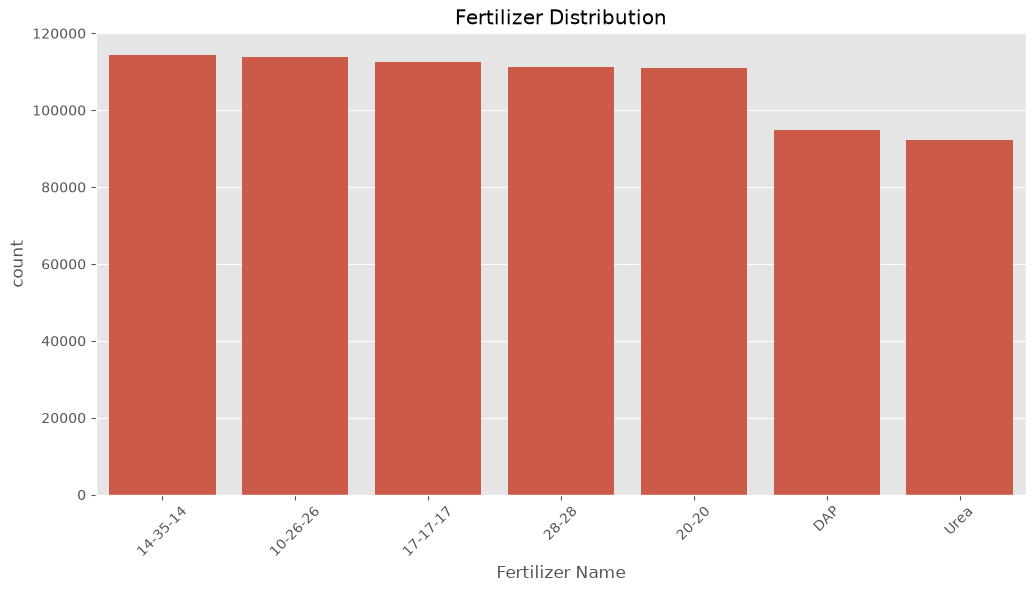

In [13]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=train,
    x="Fertilizer Name",
    order=train["Fertilizer Name"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Fertilizer Distribution")
plt.show()

# Step 9: Numerical Features

In [14]:
numerical = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous"
]

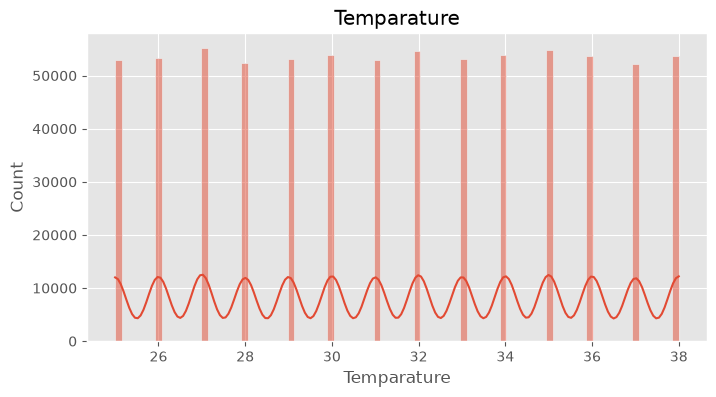

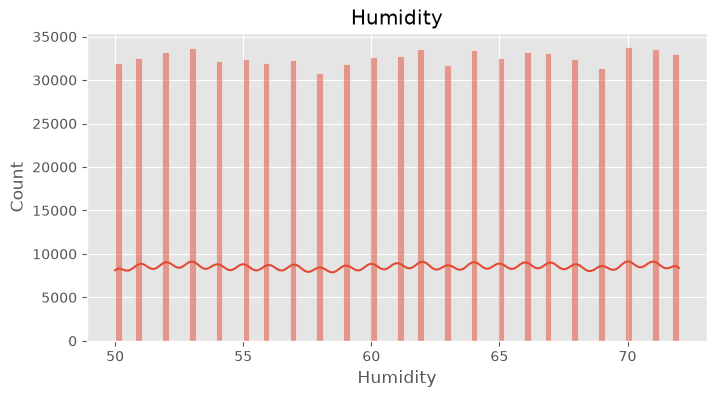

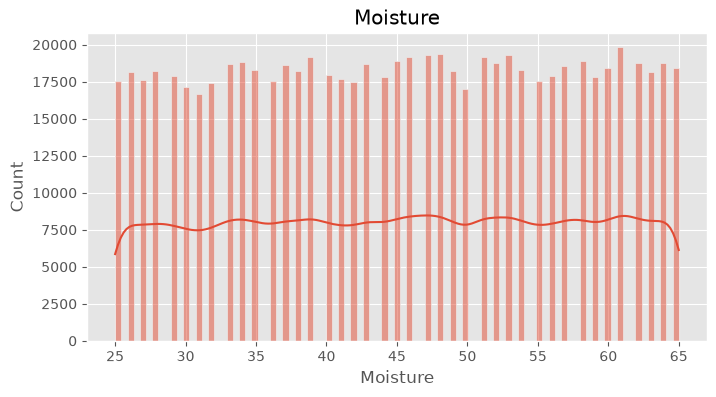

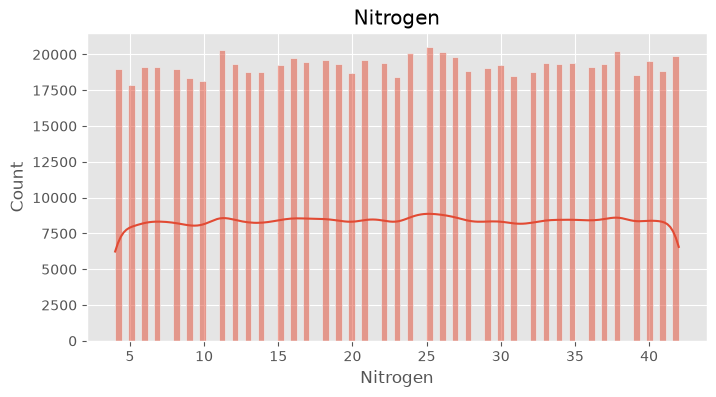

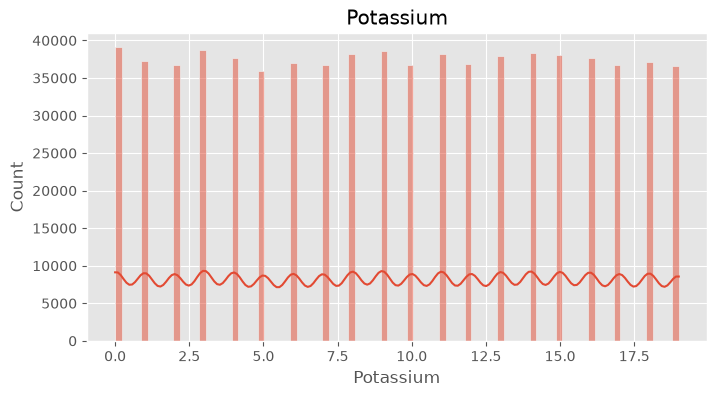

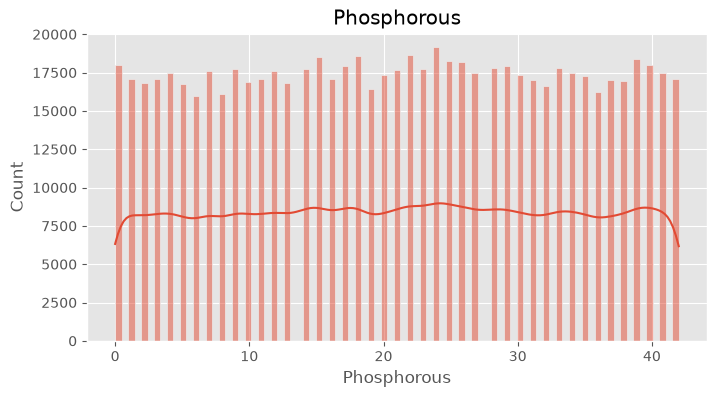

In [15]:
for col in numerical:

    plt.figure(figsize=(8,4))

    sns.histplot(train[col], kde=True)

    plt.title(col)

    plt.show()

# Step 10: Boxplots (Outliers)

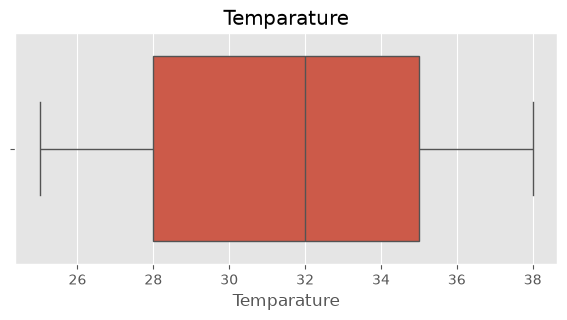

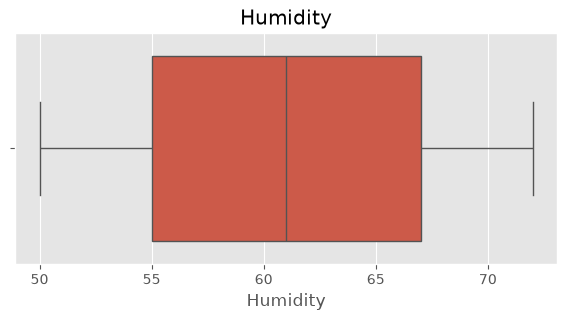

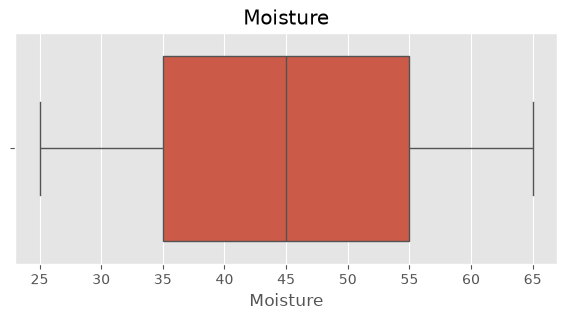

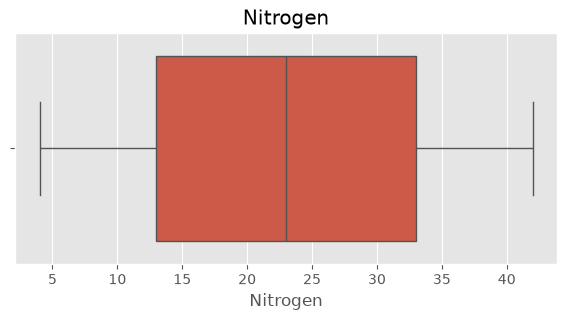

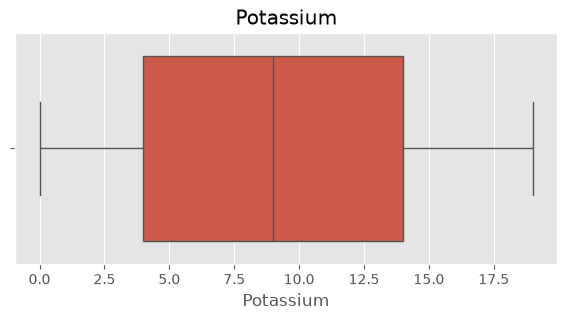

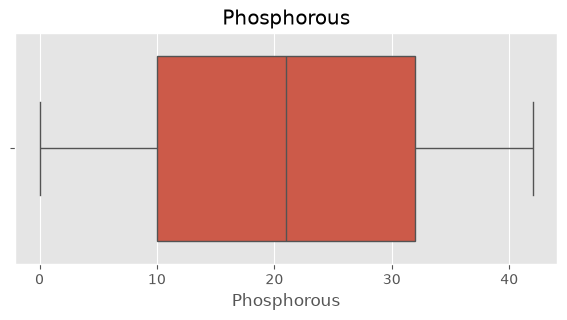

In [16]:
for col in numerical:

    plt.figure(figsize=(7,3))

    sns.boxplot(x=train[col])

    plt.title(col)

    plt.show()

# Step 11: Correlation Heatmap

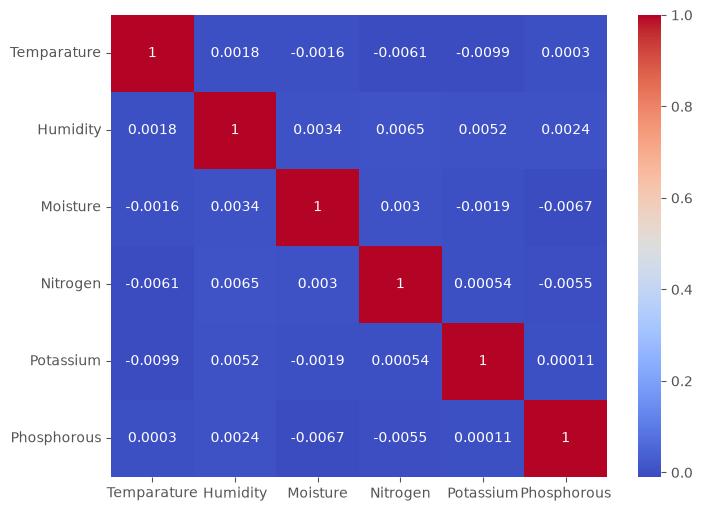

In [17]:
plt.figure(figsize=(8,6))

sns.heatmap(
    train[numerical].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

# Step 12: Categorical Features

In [18]:
categorical = [
    "Soil Type",
    "Crop Type"
]

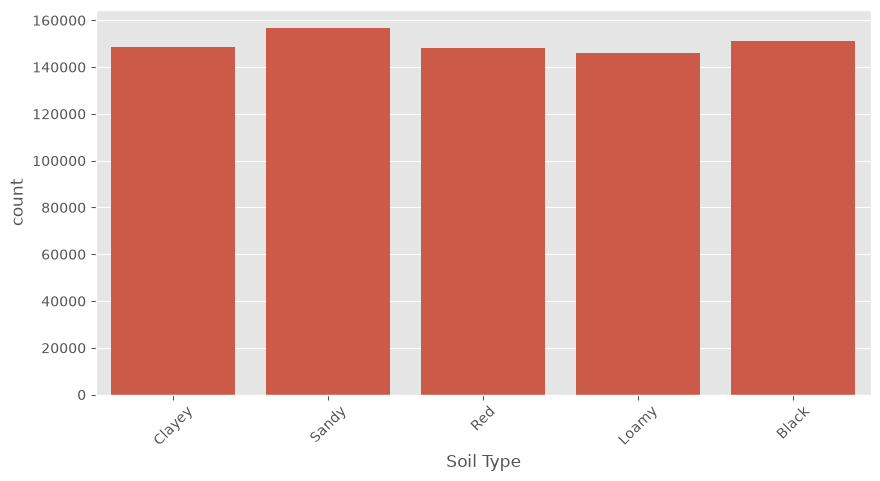

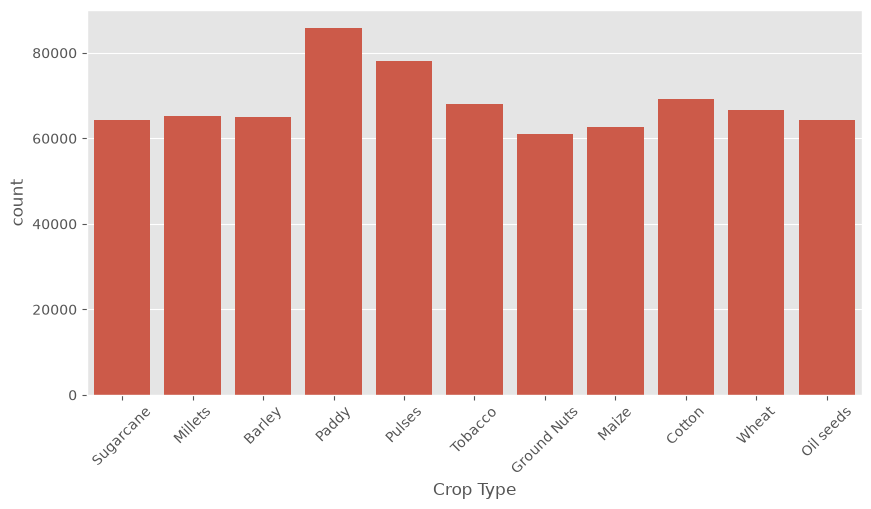

In [19]:
for col in categorical:

    plt.figure(figsize=(10,5))

    sns.countplot(data=train, x=col)

    plt.xticks(rotation=45)

    plt.show()

# Step 13: Relationship with Target

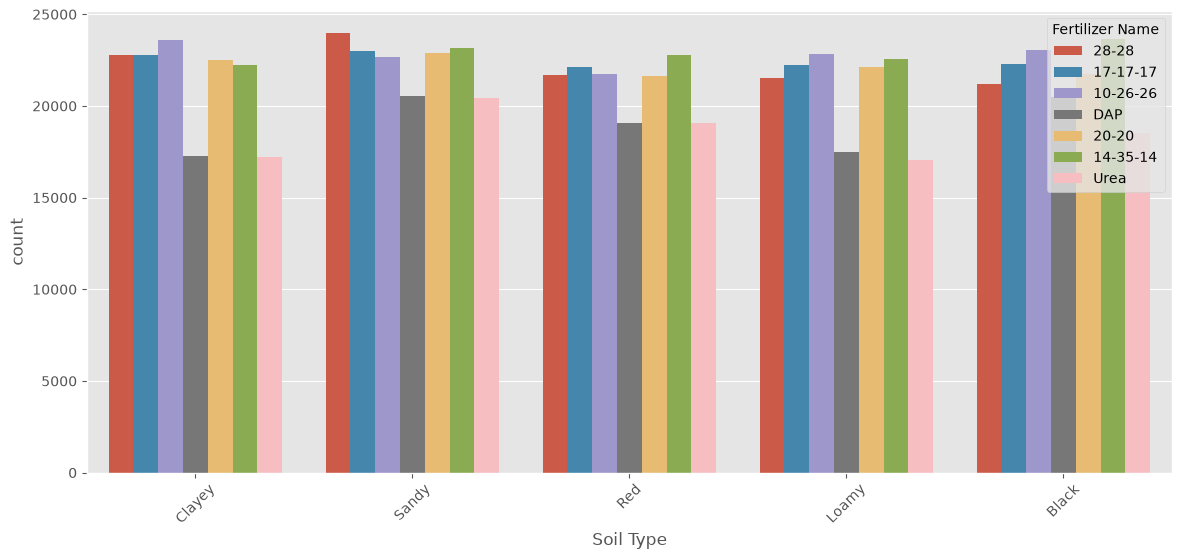

In [20]:
plt.figure(figsize=(14,6))

sns.countplot(
    data=train,
    x="Soil Type",
    hue="Fertilizer Name"
)

plt.xticks(rotation=45)

plt.show()